# snow Tutorial 7 - Temperature Tuning

The refractive index of lithium niobate changes with temperature, and with it the phase mismatch. Heating or cooling a QPM device tunes the wavelength it phase matches, and can correct a poling period that came out of fabrication slightly wrong. This notebook shows how to include temperature in snow.

We start with the usual imports and definitions.

In [1]:
import numpy as np
from numpy.fft import fft, ifft, fftshift, fftfreq
import matplotlib.pyplot as plt

import os, sys
sys.path.insert(0, os.path.abspath('..'))  # use this repo's snow package
import snow.pulses as pulses
import snow.materials as materials
import snow.waveguides as waveguides

from scipy.constants import pi, c, epsilon_0
nm = 1e-9
um = 1e-6
mm = 1e-3
ps = 1e-12
fs = 1e-15
MHz = 1e6
GHz = 1e9
THz = 1e12
pJ = 1e-12
fJ = 1e-15
mW = 1e-3
uW = 1e-6

#Larger font for plots
plt.rcParams.update({'font.size': 14})

## Temperature-dependent materials

Only some material models depend on temperature: `LN_MgO_e_T` and `LN_MgO_o_T` (MgO-doped congruent LN, Gayer et al. 2008) and `LT_SLT`. The others, such as `LN_MgO_e`, ignore `T`. Every dispersion method takes a temperature in °C: `materials.refractive_index(name, wl_um, T=...)`, `wg.neff(wl, T=...)`, `wg.beta(wl, T=...)`, `wg.beta1(wl, T=...)`, and `wg.propagate(pulse, T=...)`.

In [2]:
Ts = np.array([20, 50, 100, 150])
for name in ['LN_MgO_e', 'LN_MgO_e_T']:
    n = [materials.refractive_index(name, 1.0, T=T) for T in Ts]
    print('%-11s n(1 um) at %s C: %s' %(name, Ts, np.round(n, 5)))

LN_MgO_e    n(1 um) at [ 20  50 100 150] C: [2.15087 2.15087 2.15087 2.15087]
LN_MgO_e_T  n(1 um) at [ 20  50 100 150] C: [2.15049 2.1588  2.17438 2.19205]


**A caution about the absolute numbers.** The Gayer model gives $dn_e/dT \approx 3\times10^{-4}$ /K at 1 µm, several times larger than other published models for LN (for example Jundt 1997 for congruent LN). The coefficients in snow match the paper and its 2010 erratum. The methods in this notebook do not depend on the model, but check the tuning rates against your own measurements before relying on them.

snow also ignores thermal expansion, which changes the poling period by about $1.5\times10^{-5}$ /K and is a much smaller effect here.

## Theory

With a fixed grating $K_g$, the residual mismatch at temperature $T$ is $\Delta k'(T) = \beta(2\omega, T) - 2\beta(\omega, T) - K_g$. To first order,

$$
\Delta k'(T) \approx \frac{\partial \Delta k}{\partial T}(T - T_0),
\qquad
\eta(T) \propto \mathrm{sinc}^2\!\left(\frac{\Delta k'(T)\,L}{2}\right),
$$

so the temperature acceptance (FWHM) is $\Delta T = 5.57 / (L\,|\partial_T\Delta k|)$. The phase-matched pump wavelength moves at

$$
\frac{d\lambda}{dT} = -\frac{\partial_T \Delta k}{\partial_\lambda \Delta k}.
$$

$\partial_\lambda \Delta k$ is proportional to the GVM, so a waveguide with small GVM, which accepts a broad band of pump wavelengths (Tutorial 6), also tunes a long way in wavelength per kelvin.

## Waveguide

The waveguide of Tutorial 5, with the temperature-dependent film material, poled for SHG of 2 µm at 25 °C.

In [3]:
λp = 2*um
L = 4*mm
T0 = 25
ridge = waveguides.RidgeIndex(w_top=1800*nm, h_thinfilm=700*nm, h_etch=350*nm, tf_material='LN_MgO_e_T')
wg = waveguides.Waveguide(ridge, length=L, X0=1.1e-12)

def Δk(T, λ=λp):
    return wg.beta(λ/2, T=T) - 2*wg.beta(λ, T=T)

Kg = Δk(T0)
pp = 2*pi/Kg
print('Poling period for SHG of %0.1f um at %d C: %0.4f um' %(λp/um, T0, pp/um))

dΔk_dT = (Δk(T0 + 1) - Δk(T0 - 1))/2
dΔk_dλ = (Δk(T0, λp + 1*nm) - Δk(T0, λp - 1*nm))/(2*nm)
print('dΔk/dT = %0.1f 1/(m K)' %dΔk_dT)
print('Temperature acceptance (FWHM) for L = %0.0f mm: %0.1f K' %(L/mm, 5.57/(L*abs(dΔk_dT))))
print('Tuning of the phase-matched wavelength: %0.2f nm/K' %(-dΔk_dT/dΔk_dλ/nm))

Poling period for SHG of 2.0 um at 25 C: 5.1724 um
dΔk/dT = 76.9 1/(m K)
Temperature acceptance (FWHM) for L = 4 mm: 18.1 K
Tuning of the phase-matched wavelength: 5.34 nm/K


## Temperature tuning curve

We sweep the temperature at a fixed poling period and compare the simulated conversion with the $\mathrm{sinc}^2$ curve computed from $\Delta k(T)$. At each temperature `propagate(T=...)` uses $\beta$ at that temperature, and we also move the frame with the SH group velocity at that temperature. The pump is weak (0.1 µW) so there is no depletion.

In [4]:
#Bandwidth: pump (2 um) and second harmonic (1 um)
λ_start = 800*nm
λ_stop = 3*um
f_max = c/λ_start
f_min = c/λ_stop
BW = f_max - f_min

N = 2**10       #number of points
Δt = 1/BW       #time resolution
t = (np.arange(N) - N//2)*Δt   #time grid, centred on t = 0
f_ref = (f_max + f_min)/2      #reference frequency

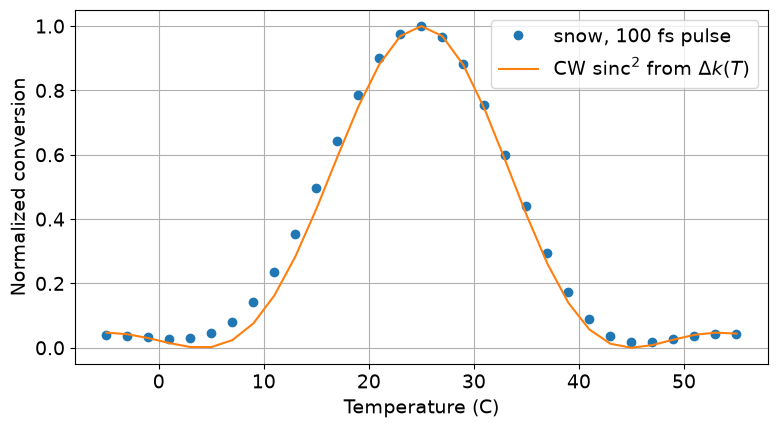

In [5]:
def sh_fraction(out, p_in, λp):
    #Fraction of the input energy above 1.5x the pump frequency
    S = np.abs(out.A)**2
    return S[out.f_abs > 1.5*c/λp].sum()/np.sum(np.abs(p_in.A)**2)

frep = 250*MHz
pump = pulses.sech_pulse(t, 100*fs, Pavg=0.1*uW, f_ref=f_ref, f0=c/λp, Npwr_dB=100, frep=frep, rng=1)

def conversion(T, Kg=Kg):
    out = wg.propagate(pump, v_ref=1/wg.beta1(λp/2, T=T), Kg=Kg, T=T).pulse
    return sh_fraction(out, pump, λp)

Tsweep = np.linspace(T0 - 30, T0 + 30, 31)
conv_T = np.array([conversion(T) for T in Tsweep])
sinc2 = np.array([np.sinc((Δk(T) - Kg)*L/(2*pi))**2 for T in Tsweep])

fig, ax = plt.subplots(figsize=(8, 4.5), tight_layout=True)
ax.plot(Tsweep, conv_T/conv_T.max(), 'o', label='snow, 100 fs pulse')
ax.plot(Tsweep, sinc2, label='CW sinc$^2$ from $\\Delta k(T)$')
ax.set_xlabel('Temperature (C)'); ax.set_ylabel('Normalized conversion')
ax.legend(); ax.grid(True)

The pulsed simulation follows the CW curve: the 100 fs pump is narrow compared with the waveguide's wavelength acceptance (Tutorial 6), so every spectral component sees nearly the same mismatch.

## Phase-matched wavelength versus temperature

The pump wavelengths that are phase matched at temperature $T$ satisfy $\Delta k(\lambda, T) = K_g$. Rather than solving for $\lambda$ at each temperature, we map the residual mismatch $\Delta k - K_g$ over wavelength and temperature and draw its zero contour. This also shows something a root finder would hide.

GVM between λ and λ/2 changes sign at λ = 2.14 um


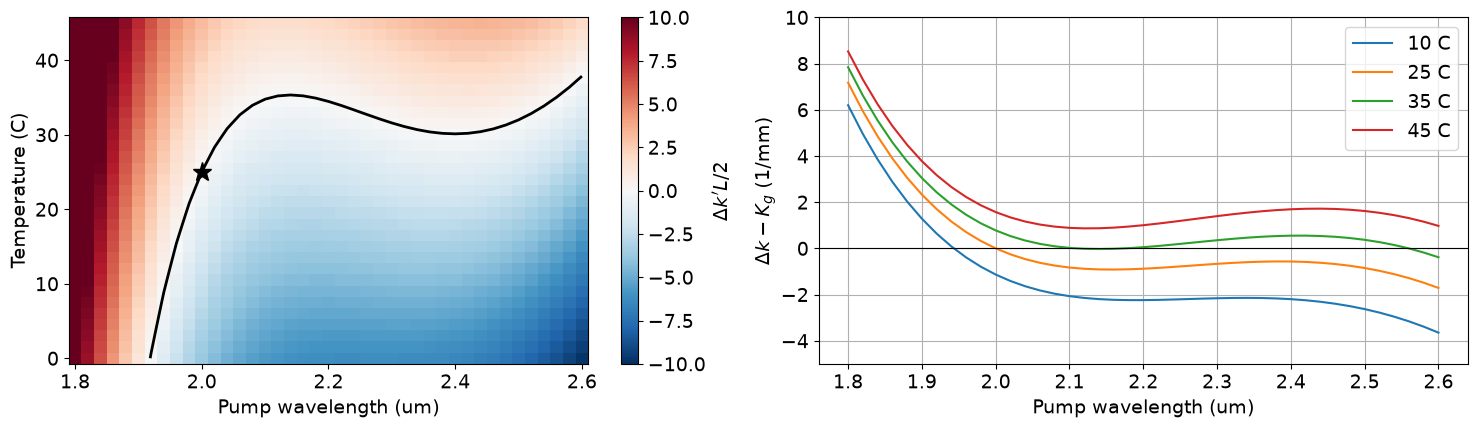

In [6]:
λmap = np.linspace(1.8, 2.6, 41)*um
Tmap = np.linspace(0, 45, 31)
mismatch = np.array([Δk(T, λmap) - Kg for T in Tmap])   #shape (T, λ)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), tight_layout=True)
im = ax1.pcolormesh(λmap/um, Tmap, mismatch*L/2, cmap='RdBu_r', vmin=-10, vmax=10, shading='auto')
ax1.contour(λmap/um, Tmap, mismatch, levels=[0], colors='k', linewidths=2)
fig.colorbar(im, ax=ax1, label="$\\Delta k' L/2$")
ax1.plot(λp/um, T0, 'k*', ms=14)
ax1.set_xlabel('Pump wavelength (um)'); ax1.set_ylabel('Temperature (C)')

for T in [10, 25, 35, 45]:
    ax2.plot(λmap/um, (Δk(T, λmap) - Kg)/1e3, label='%d C' %T)
ax2.axhline(0, color='k', lw=0.8)
ax2.set_ylim(-5, 10)
ax2.set_xlabel('Pump wavelength (um)'); ax2.set_ylabel("$\\Delta k - K_g$ (1/mm)")
ax2.legend(); ax2.grid(True)

gvm_λ = wg.beta1(λmap/2, T=T0) - wg.beta1(λmap, T=T0)
k = np.nonzero(np.diff(np.sign(gvm_λ)))[0][0]
print('GVM between λ and λ/2 changes sign at λ = %0.2f um' %(λmap[k]/um))

The black line is the phase-matching curve, and it is not a straight line. Near 2 µm it tunes at the 5.3 nm/K computed above. At about 2.14 µm and 35 °C it turns over, and between 30 °C and 35 °C three pump wavelengths are phase matched at once. Above 35 °C the 2 µm branch is gone and the only phase-matched wavelengths in this range lie beyond 2.5 µm.

The turning points are where $\partial_\lambda \Delta k = 0$. That derivative is proportional to the GVM between $\lambda$ and $\lambda/2$, which changes sign at 2.14 µm in this waveguide (right panel: $\Delta k(\lambda)$ has a minimum there). Near a turning point the wavelength tuning rate $-\partial_T\Delta k/\partial_\lambda\Delta k$ diverges and the wavelength acceptance is very broad: the zero-GVM regime of Tutorial 6.

## Correcting a fabrication error

Suppose the fabricated poling period is 20 nm shorter than designed. At 25 °C the conversion drops. $K_g$ is now larger, and since $\Delta k$ grows with temperature, heating the chip restores $\Delta k(T) = K_g$. We find that temperature with `brentq`.

In [7]:
from scipy.optimize import brentq

Kg_fab = 2*pi/(pp - 20*nm)
T_fix = brentq(lambda T: Δk(T) - Kg_fab, -50, 200)

c_design = conversion(T0)
print('Design period, %d C:       %0.3f %% conversion' %(T0, 100*c_design))
print('Period -20 nm, %d C:       %0.3f %%' %(T0, 100*conversion(T0, Kg_fab)))
print('Period -20 nm, %0.1f C:   %0.3f %%' %(T_fix, 100*conversion(T_fix, Kg_fab)))

Design period, 25 C:       0.378 % conversion
Period -20 nm, 25 C:       0.001 %
Period -20 nm, 82.9 C:   0.391 %


A 20 nm error in a 5.17 µm period is 0.4 %, yet without correction it loses nearly all the conversion. Heating by about 60 K (with this model's thermo-optic coefficients) brings it back. Errors larger than this would need a temperature beyond what is practical, or a different poling period on the same chip.

## Summary

- Use a temperature-dependent material (`LN_MgO_e_T`, `LN_MgO_o_T`, `LT_SLT`) and pass `T` to the dispersion methods and to `propagate`.
- The temperature acceptance is $5.57/(L|\partial_T\Delta k|)$, and the phase-matched wavelength tunes at $-\partial_T\Delta k/\partial_\lambda\Delta k$.
- Temperature can compensate small poling-period errors.
- Check the absolute thermo-optic rates against measurements; the Gayer model's are large.